<a href="https://colab.research.google.com/github/ayeshamohammad2510-sys/research-heart/blob/main/100_Samples_(Fig_1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install wfdb
import wfdb, numpy as np, matplotlib.pyplot as plt, sklearn
print("wfdb", wfdb.__version__, "| sklearn", sklearn.__version__)

wfdb 4.3.1 | sklearn 1.6.1


sampling rate: 360 Hz
channels: ['MLII', 'V5']
beats found in these 10 seconds: 14
their labels: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N']


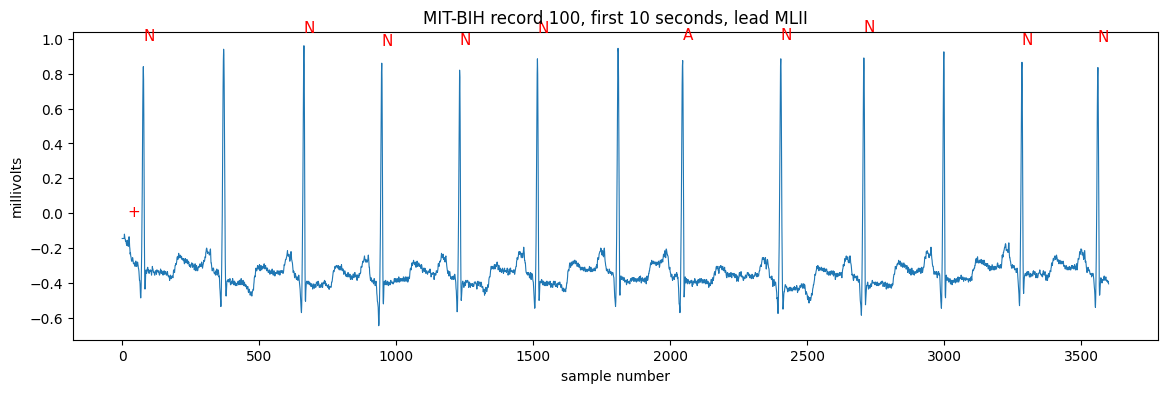

In [2]:
import wfdb, matplotlib.pyplot as plt

# Stream record 100 directly from PhysioNet (no download needed)
# 3600 samples = 10 seconds at 360 Hz
rec = wfdb.rdrecord('100', pn_dir='mitdb', sampfrom=0, sampto=3600)
ann = wfdb.rdann('100', 'atr', pn_dir='mitdb', sampfrom=0, sampto=3600)

print("sampling rate:", rec.fs, "Hz")
print("channels:", rec.sig_name)
print("beats found in these 10 seconds:", len(ann.sample))
print("their labels:", ann.symbol)

plt.figure(figsize=(14, 4))
plt.plot(rec.p_signal[:, 0], linewidth=0.8)
for s, sym in zip(ann.sample, ann.symbol):
  plt.annotate(sym, (s, rec.p_signal[s, 0] + 0.15), color='red', fontsize=11)
plt.title("MIT-BIH record 100, first 10 seconds, lead " + rec.sig_name[0])
plt.xlabel("sample number"); plt.ylabel("millivolts")
plt.show()